Импорт библиотек

In [44]:
#для бенчмаркинга
import time
import random
import statistics
#для графиков
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
#для таблицы
from IPython.display import display
#чтобы графики остались в jupyter ноутбуке
%matplotlib inline


Stupid Sort\
    Теоретическое время: $O(N^3)$ в среднем, $O(N^3)$ в худшем случае (все наоборот), $O(N)$ в лучшем (уже отсортированный массив), т. е. это адаптивная сортировка\
    Память: $O(1)$ (in-place)\
    Сортировка устойчивая.\
    Возвращает отсортированный массив, число сравнений comparisons и число перезаписей writes.

In [45]:
def stupid_sort(arr: list[int | float]) -> tuple[list[int | float], int, int]:
    comparisons = 0
    writes = 0
    
    i = 0
    #проходим по списку, пока не встретим неотсортированные элементы, потом возвращаемся в начало
    while i < len(arr) - 1:
        comparisons += 1
        #меняем местами неотсортированные элементы
        if arr[i] > arr[i + 1]:
            arr[i], arr[i + 1] = arr[i + 1], arr[i]
            writes += 1
            i = 0
        else:
            i += 1
            
    return arr, comparisons, writes

Insertion Sort\
    Теоретическое время: $O(N^2)$ в среднем, $О(N^2)$ в худшем случае (все наоборот), $O(N)$ в лучшем случае (уже отсортированный массив), т. е. это адаптивная сортировка\
    Память: $O(1)$ (in-place)\
    Сортировка устойчивая.\
    Возвращает отсортированный массив, число сравнений comparisons и число перезаписей writes.

In [46]:
def insertion_sort(arr: list[int | float]) -> tuple[list[int | float], int, int]:
    comparisons = 0
    writes = 0
    
    for i in range(1, len(arr)):
        #сохраняем элемент в переменную key
        key = arr[i]
        j = i - 1
        #двигаем элементы вправо, если они больше key, пока не дошли до начала списка
        while j >= 0:
            comparisons += 1
            if arr[j] > key:
                # cдвигаем элемент вправо
                arr[j + 1] = arr[j]
                writes += 1
                j -= 1
            else:
                break
                
        # помещаем key на нужную позицию
        arr[j + 1] = key
        writes += 1
        
    return arr, comparisons, writes

Merge Sort\
    Теоретическое время: $O(NlogN)$ на любом массиве, т. е. сортировка не адаптивная\
    Память: $O(N)$ (out-of-place)\
    Сортировка устойчивая.\
    Возвращает отсортированный массив, число сравнений comparisons и число перезаписей writes.

In [47]:
def merge_sort(arr: list[int | float]) -> tuple[list[int | float], int, int]:
    if len(arr) <= 1:
        return arr, 0, 0
    #разбиваем массив на 2 (рекурсивно)
    mid = len(arr) // 2
    first_half_sorted, comp_1, writes_1 = merge_sort(arr[:mid])
    second_half_sorted, comp_2, writes_2 = merge_sort(arr[mid:])
    #сливаем 2 отсортированных массива в один
    merged_arr, merge_comp, merge_writes = merge(first_half_sorted, second_half_sorted)
    total_comp = comp_1 + comp_2 + merge_comp
    total_writes = writes_1 + writes_2 + merge_writes

    return merged_arr, total_comp, total_writes

#функция сливает 2 массива в 1
def merge(arr_1: list[int | float], arr_2: list[int | float]) -> tuple[list[int | float], int, int]:
    arr_merged = []
    i = j = 0
    comparisons = 0
    writes = 0

    while i < len(arr_1) and j < len(arr_2):
        comparisons += 1
        if arr_1[i] <= arr_2[j]:
            arr_merged.append(arr_1[i])
            i += 1
        else:
            arr_merged.append(arr_2[j])
            j += 1
        writes += 1
    #добавляем в новый массив элемент, оставшийся в одном из старых массивов
    arr_merged.extend(arr_1[i:])
    writes += len(arr_1) - i
    
    arr_merged.extend(arr_2[j:])
    writes += len(arr_2) - j
    
    return arr_merged, comparisons, writes


Бенчмаркинг

In [48]:

def generate_data(n: int, distribution_type: str) -> list[int]:
    """
    Генерирует массивы данных с разными распределениями.
    Возвращает 1 массив данных.
    """
    if distribution_type == "Uniform Random": #случайный массив
        return [random.randint(-10000, 10000) for _ in range(n)]
    elif distribution_type == "Sorted": #отсортированный массив
        return list(range(1, n + 1))
    elif distribution_type == "Reversed": # массив, отсортированный в обратном порядке
        return list(range(n, 0, -1))
    elif distribution_type == "Nearly Sorted": #в массиве 5% элементов случайно перемешаны
        arr = list(range(1, n + 1))
        num_swaps = max(1, int(n * 0.05) // 2) # 1 - для очень маленьких массивов
        for _ in range(num_swaps):
            i, j = random.randint(0, n - 1), random.randint(0, n - 1)
            arr[i], arr[j] = arr[j], arr[i]
        return arr
    elif distribution_type == "Many Duplicates": #массив с большим количеством повторяющихся элементов
        return [random.choice([1, 2, 3, 4, 5]) for _ in range(n)]

def run_benchmark(sort_func, n_sizes: list[int], repeats: int = 5): #по умолчанию 5 раз тестируется каждая сортировка
    """
    Проводит замеры для одной сортировки.
    Возвращает список словарей со статистикой.
    """
    distributions = [
        "Uniform Random", "Sorted", "Reversed", 
        "Nearly Sorted", "Many Duplicates"
    ]
    
    results = []
    for dist_type in distributions: #перебирает типы массивов
        for n in n_sizes: #перебирает длины массивов

            if sort_func.__name__ == "stupid_sort" and n > 500:
                continue              #stupid sort не тестируется на массивах с длиной больше 500
            
            times = []
            comps = []
            swaps = []
            for seed in range(repeats): 
                # 5 раз тестируется сортировка на различных массивах одной длины и с одинаковым распределением
                random.seed(seed) #каждая сортировка будет получать идентичные массивы
                data = generate_data(n, dist_type)
                data_copy = data.copy() #копируем массив, чтобы каждая сортировка получала на вход неотсортированный
                
                #замер времени
                t_start = time.perf_counter()
                _, cmp_cnt, swap_cnt = sort_func(data_copy) #  "_"  написано тк сам отсортированный массив не нужен
                t_end = time.perf_counter()
                
                times.append(t_end - t_start)
                comps.append(cmp_cnt)
                swaps.append(swap_cnt)
            
            results.append({     #добавляем словарь в список results
                "Алгоритм": sort_func.__name__,
                "Распределение": dist_type,
                "N": n,
                "Среднее время (с)": statistics.mean(times),
                "Отклонение (с)": statistics.stdev(times) if len(times) > 1 else 0.0,
                "Сравнения": int(statistics.mean(comps)),
                "Перезаписи": int(statistics.mean(swaps))
            })
    return results

Графики

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# шаблоны для аппроксимации
def fit_n2(n, c):
    return c * n**2

def fit_nlogn(n, c):
    return c * n * np.log2(np.maximum(n, 1e-10)) # под логарифмом никогда не будет 0

def plot_benchmark_results(results_list: list[dict], target_distribution: str = "Uniform Random"):
    """
    Строит 3 графика (линейный, log-log, fitting) для выбранного распределения (по умолчанию для случайного массива)
    """
    df = pd.DataFrame(results_list) #таблица вместо списка словарей
    df_dist = df[df["Распределение"] == target_distribution] #отбираются строки которые относятся к конкретному распределению
    
    if df_dist.empty:
        print(f"Нет данных для распределения: {target_distribution}")
        return

    # График 1: линейный
    plt.figure(figsize=(10, 6))
    for algo in df_dist["Алгоритм"].unique(): #из таблицы извлекаются данные для конкретной сортировки
        df_algo = df_dist[df_dist["Алгоритм"] == algo]
        plt.errorbar(df_algo["N"], df_algo["Среднее время (с)"], 
                     yerr=df_algo["Отклонение (с)"], label=algo, fmt='-o', capsize=4)
        
    plt.title(f"Время от размера массива (Линейный масштаб) | {target_distribution}") #автоматически подставляется название распределения
    plt.xlabel("Размер массива, N (элементов)")
    plt.ylabel("Время выполнения, T (с)")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # График 2: Log-Log
    plt.figure(figsize=(10, 6))
    for algo in df_dist["Алгоритм"].unique():
        df_algo = df_dist[df_dist["Алгоритм"] == algo]
        df_algo = df_algo[df_algo["Среднее время (с)"] > 0]
        plt.errorbar(df_algo["N"], df_algo["Среднее время (с)"], 
                     yerr=df_algo["Отклонение (с)"], label=algo, fmt='-o', capsize=4)
        
    plt.xscale('log') #переключение на логарифмический масштаб
    plt.yscale('log')
    plt.title(f"Время от размера (Log-Log масштаб) | {target_distribution}")
    plt.xlabel("Размер массива, N (элементов)")
    plt.ylabel("Время выполнения, T (с)")
    plt.grid(True, which="both", ls="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # График 3: fitting
    plt.figure(figsize=(10, 6))
    for algo in df_dist["Алгоритм"].unique():
        df_algo = df_dist[df_dist["Алгоритм"] == algo]
        n_vals = df_algo["N"].values
        t_vals = df_algo["Среднее время (с)"].values
        
        p = plt.plot(n_vals, t_vals, 'o', label=f"{algo} (эксп.)")
        color = p[0].get_color()
        
        try: # чтобы программа продолжила работу, если возникли ошибки при аппроксимации
            if algo in ["merge_sort", "quick_sort", "heap_sort"]:
                popt, _ = curve_fit(fit_nlogn, n_vals, t_vals)
                plt.plot(n_vals, fit_nlogn(n_vals, *popt), '--', color=color, label=f"fit: O(N log N)")
            elif algo in ["insertion_sort", "bubble_sort", "selection_sort", "stupid_sort"]:
                popt, _ = curve_fit(fit_n2, n_vals, t_vals)
                plt.plot(n_vals, fit_n2(n_vals, *popt), '--', color=color, label=f"fit: O(N^2)")
        except Exception as e:
            print(f"Не удалось построить аппроксимацию для {algo}: {e}")

    plt.title(f"Теоретическая аппроксимация (Fitting) | {target_distribution}")
    plt.xlabel("Размер массива, N (элементов)")
    plt.ylabel("Время выполнения, T (с)")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


Запуск тестирования

Тестирую...
Протестировал. Строю графики...


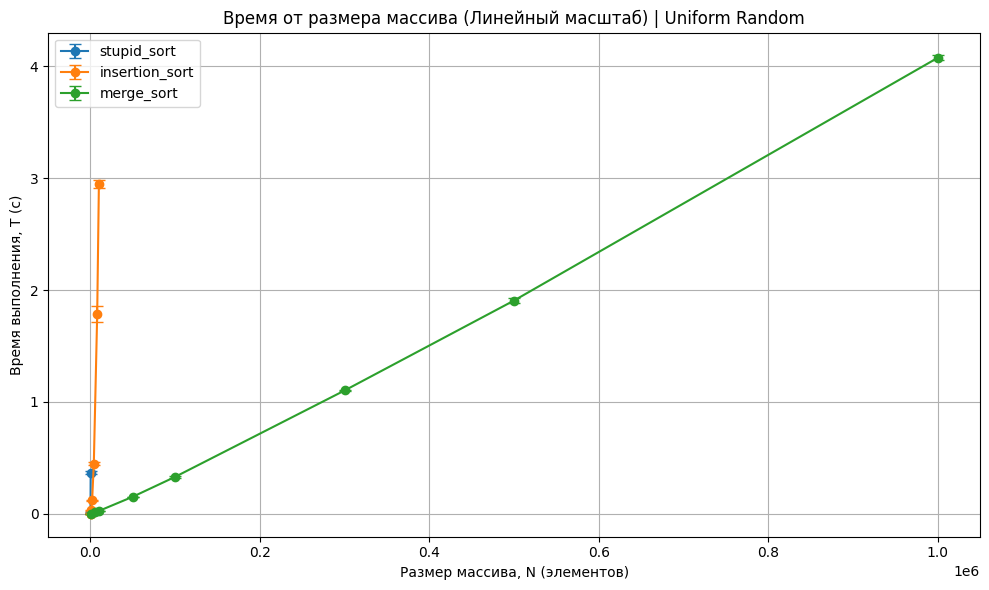

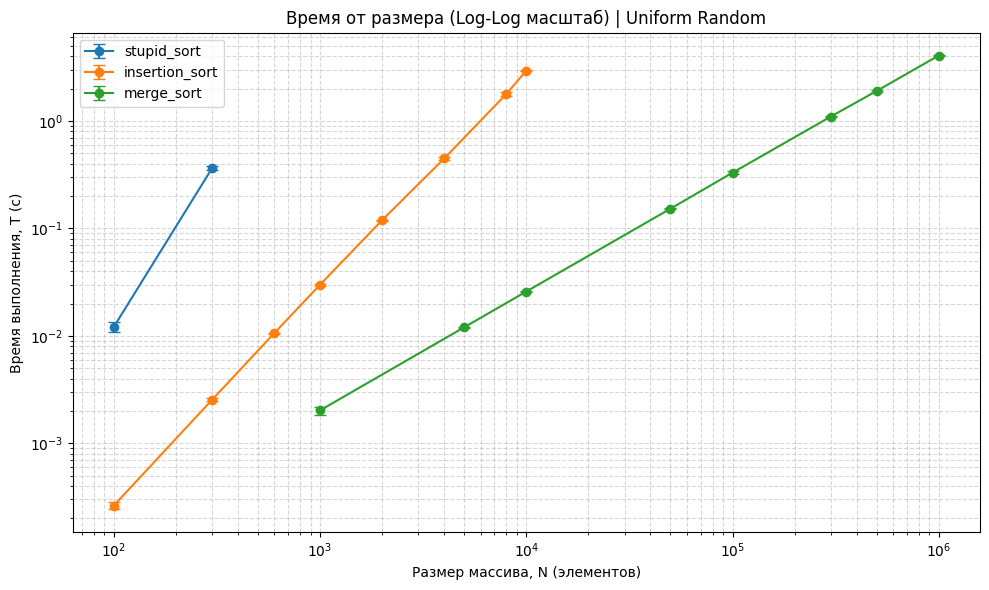

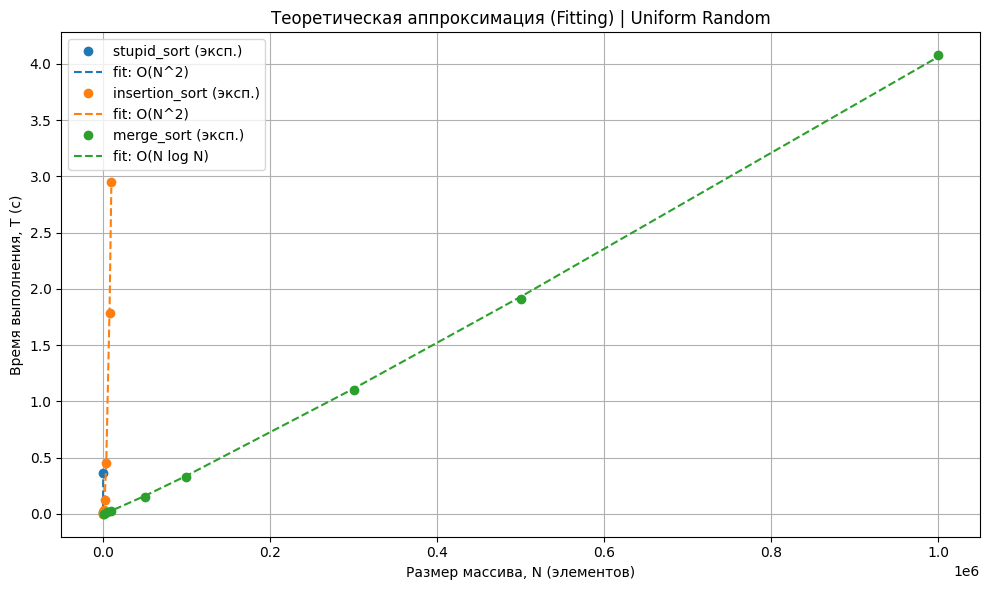

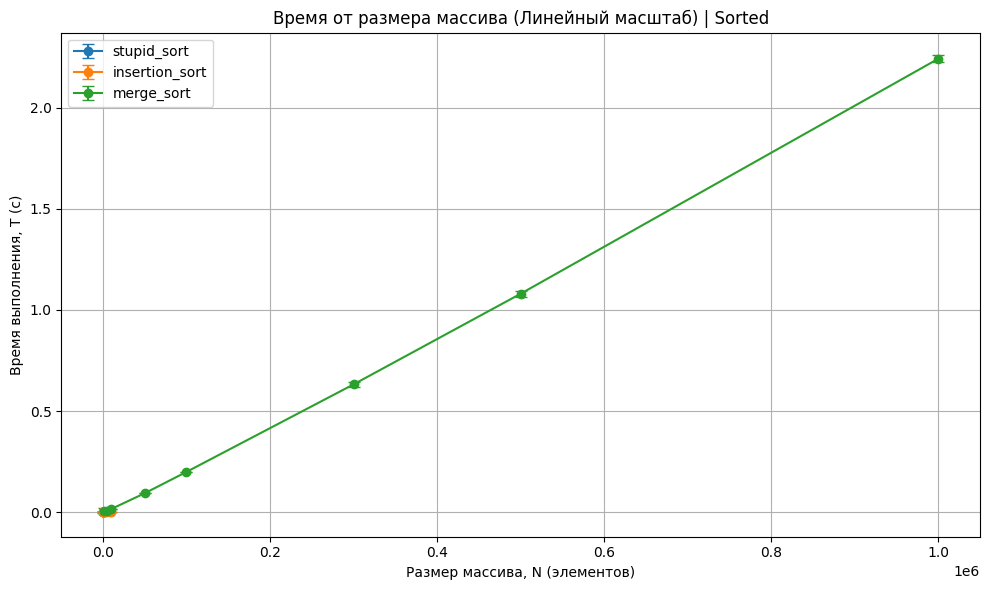

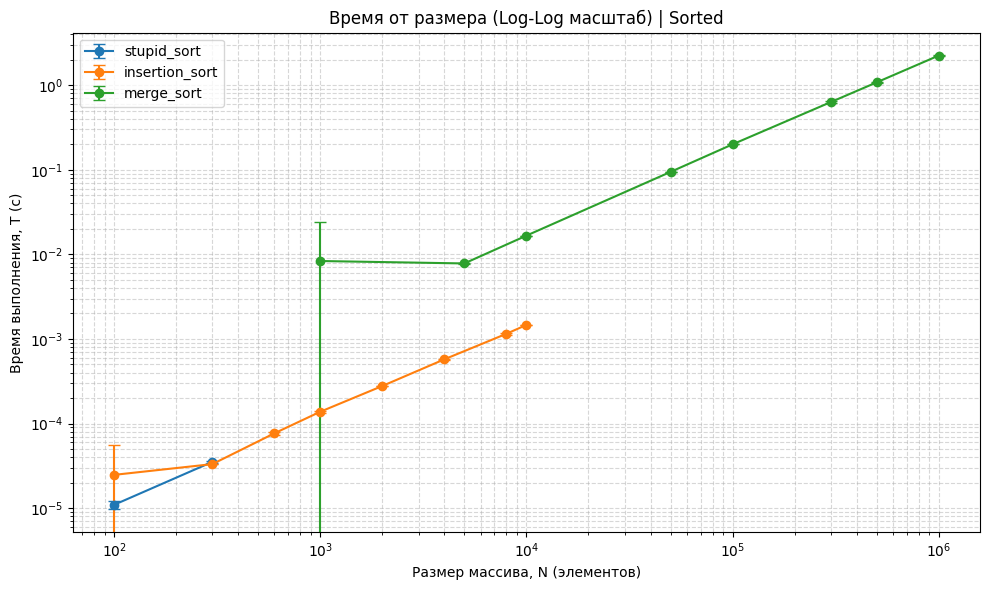

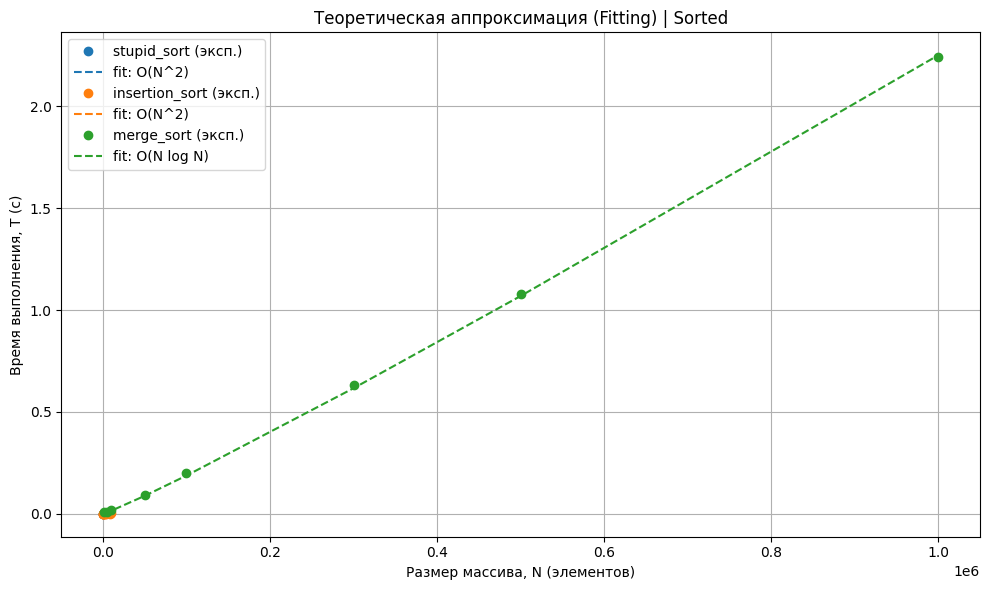

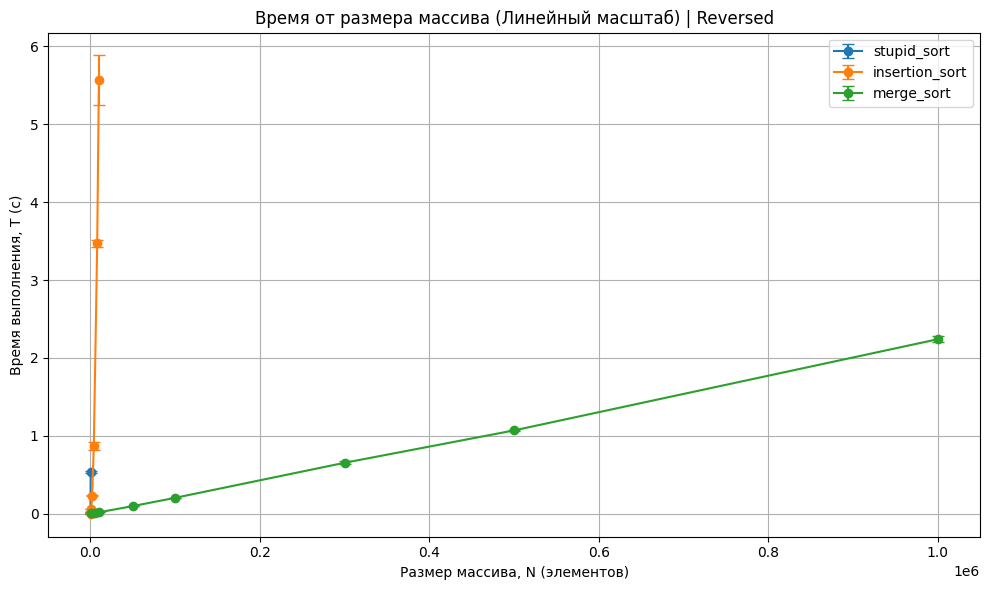

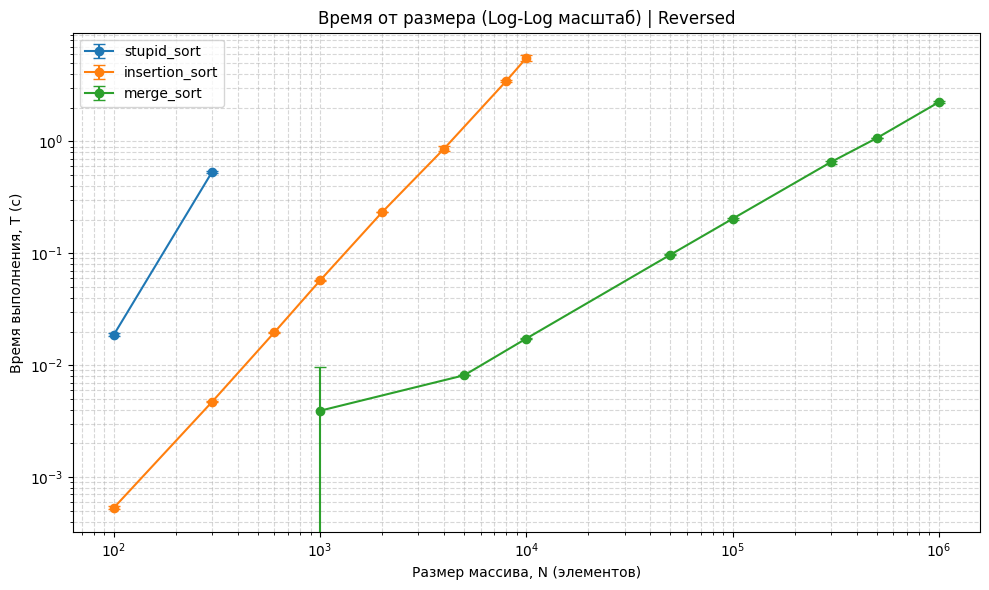

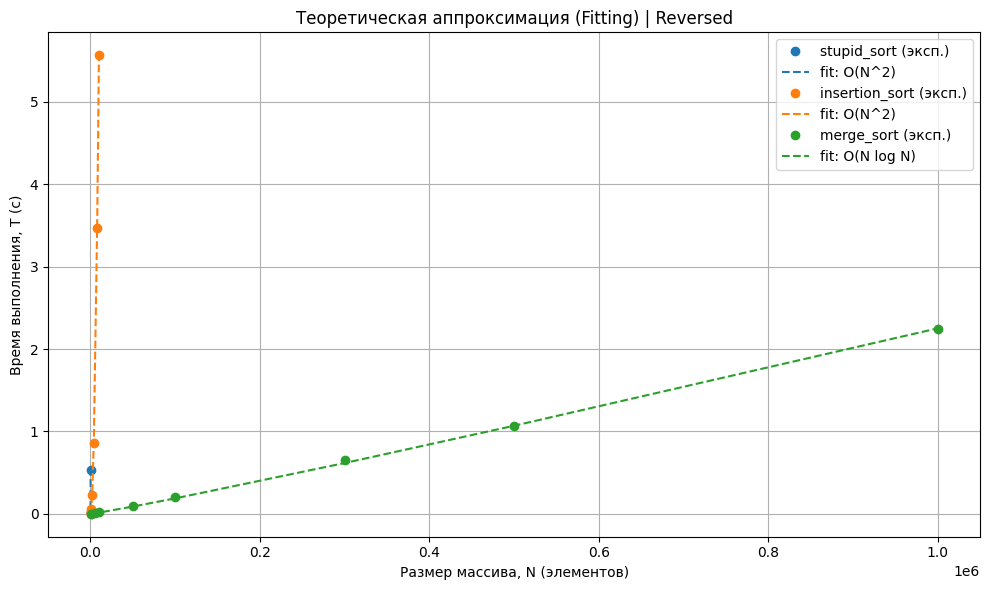

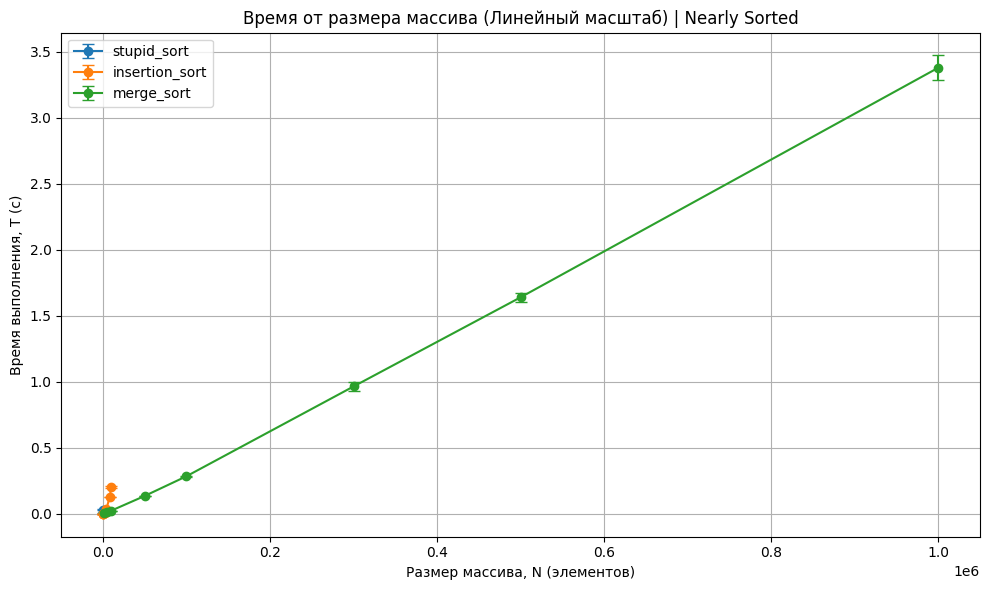

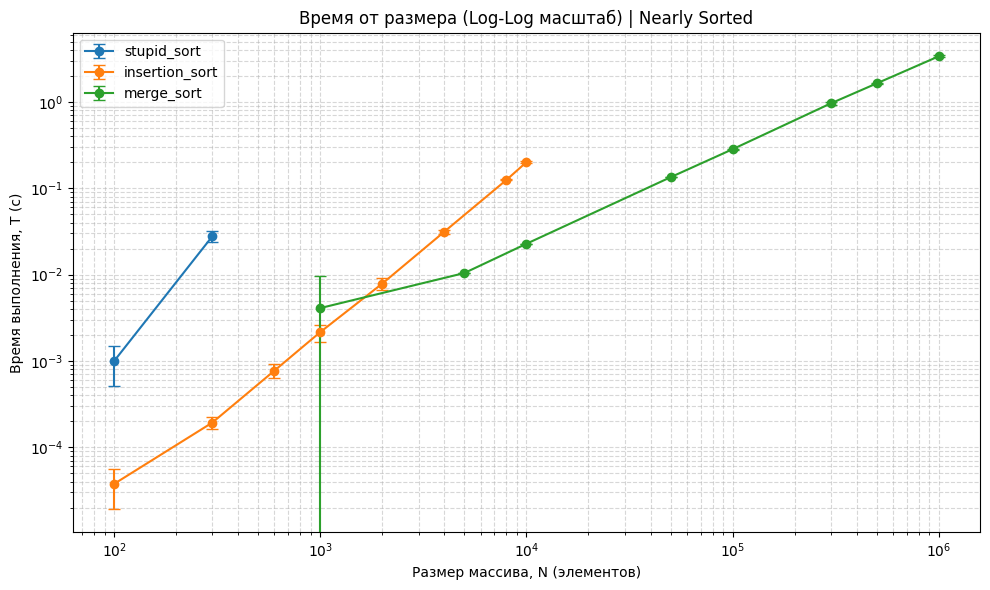

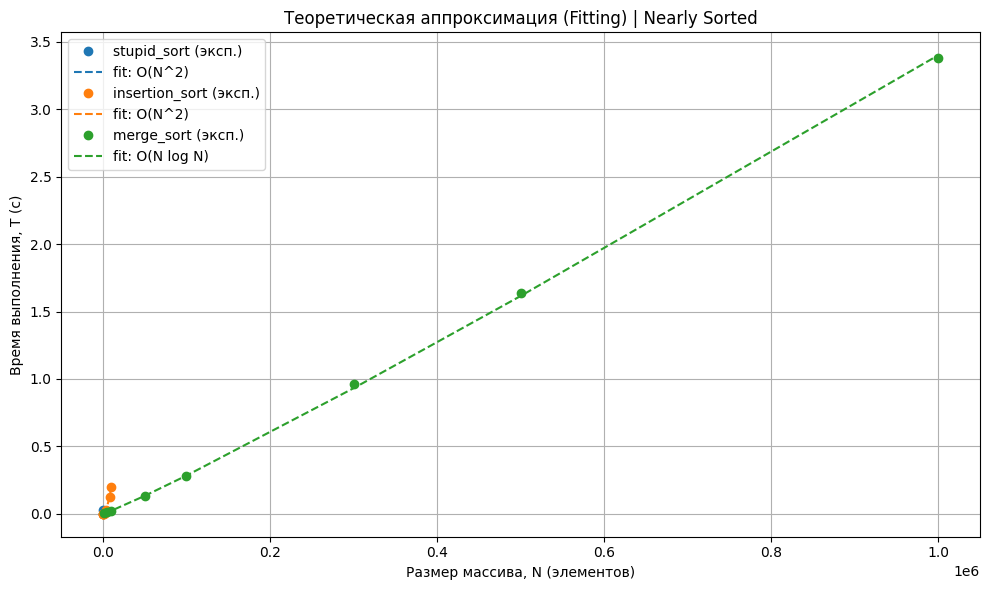

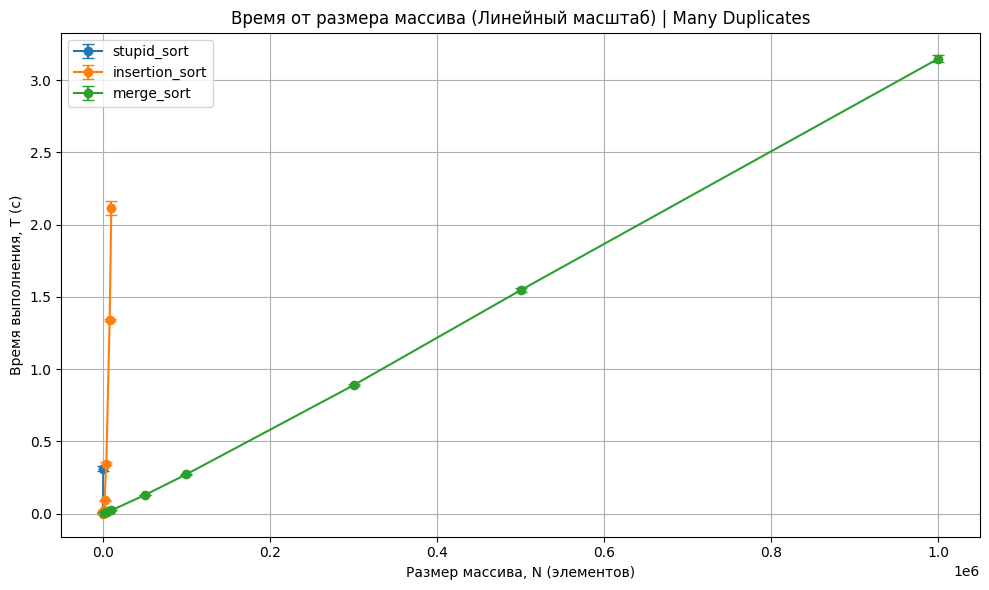

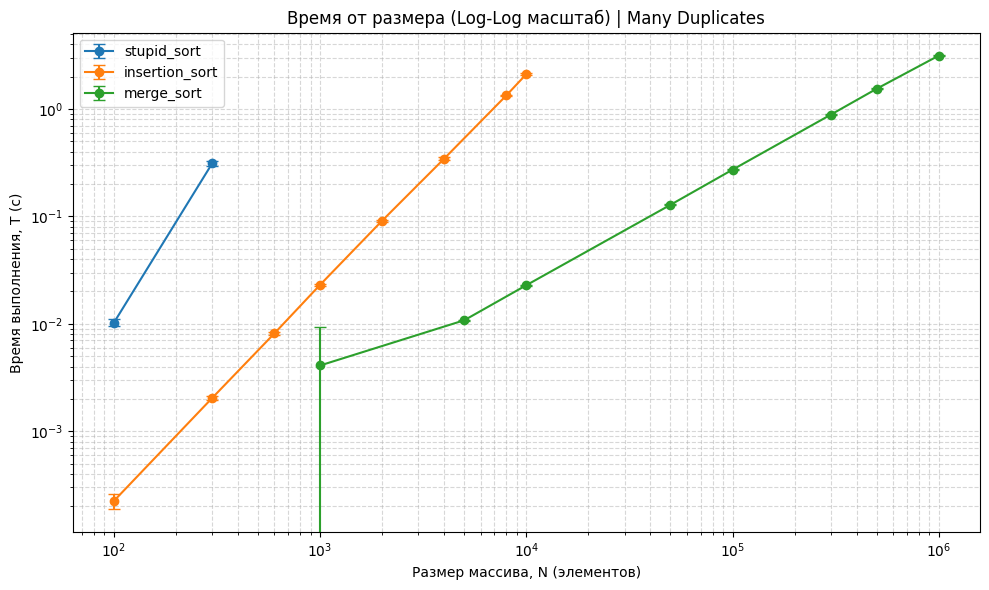

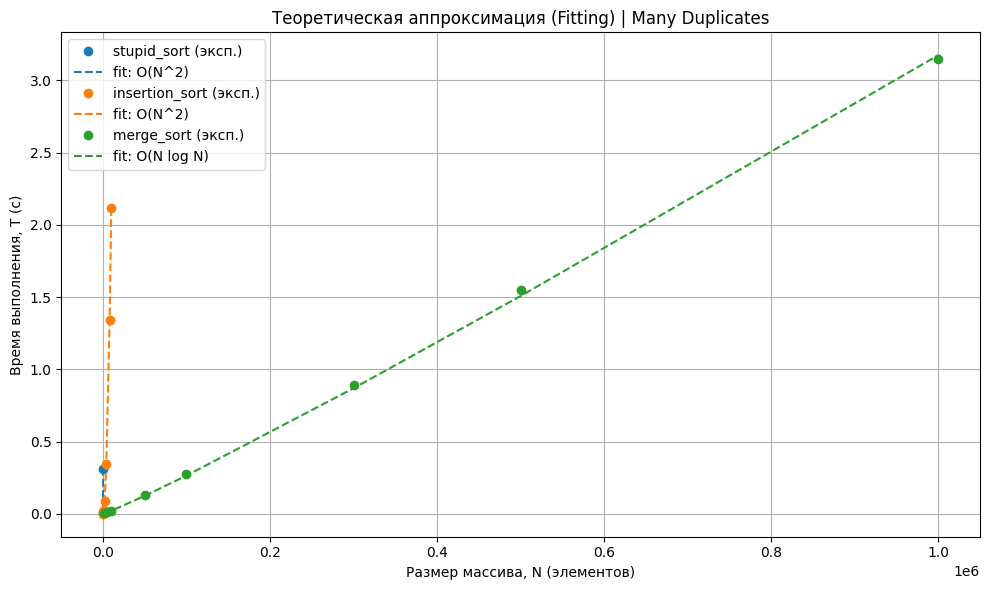

,Алгоритм,Распределение,N,Среднее время (с),Отклонение (с),Сравнения,Перезаписи
0,stupid_sort,Uniform Random,100,0.012134,1.216712e-03,110503,2454
1,stupid_sort,Uniform Random,300,0.365841,1.382512e-02,3093823,23437
2,stupid_sort,Sorted,100,0.000011,1.275470e-06,99,0
3,stupid_sort,Sorted,300,0.000035,9.108144e-07,299,0
4,stupid_sort,Reversed,100,0.018727,5.622419e-04,166749,4950
5,stupid_sort,Reversed,300,0.536366,1.032445e-02,4500249,44850
6,stupid_sort,Nearly Sorted,100,0.000994,4.818328e-04,8822,182
7,stupid_sort,Nearly Sorted,300,0.027831,3.801300e-03,229122,1497
8,stupid_sort,Many Duplicates,100,0.010219,7.760457e-04,89871,1929
9,stupid_sort,Many Duplicates,300,0.312402,1.517647e-02,2634591,18909


In [50]:
#Сетки длин массивов
n_quadratic = [100, 300, 600, 1000, 2000, 4000, 8000, 10000]
n_fast = [1000, 5000, 10000, 50000, 100000, 300000, 500000, 1000000]

# запуск замеров
print("Тестирую...")
stats_stupid = run_benchmark(stupid_sort, n_quadratic)
stats_insertion = run_benchmark(insertion_sort, n_quadratic)
stats_merge = run_benchmark(merge_sort, n_fast)

# объединение результатов в один список
all_results = stats_stupid + stats_insertion + stats_merge
print("Протестировал. Строю графики...")

# вывод графиков для 5 распределений
distributions = [
    "Uniform Random", "Sorted", "Reversed", 
    "Nearly Sorted", "Many Duplicates"
]

for dist in distributions:
    plot_benchmark_results(all_results, target_distribution=dist)

#вывод таблицы
df_results = pd.DataFrame(all_results)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
display(df_results)

Выводы:
1. fool sort и insertion sort лучшее время показали на массивах sorted. По графику в логарифмическом масштабе можно определить, что коэффициент наклона прямых около 1, т. е. время работы $O(N)$.
Худшее время эти сортировки показали на reversed массивах. По графику в логарифмическом масштабе для случайных массивов можно оценить коэффициенты наклонов прямых, у insertion sort это примерно 2, у fool sort примерно 3, т. е. время работы $O(N^2)$ и $O(N^3)$. Fool sort и insertion sort являются адаптивными.
2. merge sort на различных массивах показывает время $O(NlogN)$ и является неадаптивной.
3. На всех распределениях, кроме sorted и nearly sorted, merge sort была быстрее, чем fool sort и insertion sort. На длине $10^3$ с распределением nearly sorted и при длинах $10^3$ - $10^4$ с распределением sorted insertion sort была быстрее, чем merge sort.